# Agenda: Exploring our geospatial data for trends with house rent. 

In [10]:
import pandas as pd
from geospatial_functions import find_SA2
import geopandas as gpd
shapefile_path = '../data_to_use/geospatial_data/Vic_Area_Zones/Vic_Area_Zones.shp'
SA2_zones = gpd.read_file(shapefile_path)
properties_data = pd.read_csv("../data_to_use/preprocessed_data/cleaned_properties.csv")

properties_data["SA2"] = properties_data.apply(
    lambda row: find_SA2(SA2_zones, row["latitude"], row["longitude"]),
    axis=1,
)

properties_data.head()

/tmp/ipykernel_66591/3056048288.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  properties_data["SA2"] = properties_data.apply(


,property_id,latitude,longitude,street_address,suburb,postcode,weekly_rent_number,property_type,bedrooms,bathrooms,...,services_available_solar_power,services_available_water,services_heating,spa_outside,spa_spa,sport_gym,sport_pool,sport_tennis_court,views_garden_views,SA2
0,515812,-37.869108,144.990422,"108/126 Chapel Street,",st kilda,3182,550.0,Apartment,1,1,...,0,0,0,0,0,0,0,0,0,St Kilda East
1,802350,-37.802986,144.961405,"24 Barkly Place,",carlton,3053,360.0,Studio,1,1,...,0,0,0,0,0,0,0,0,0,Carlton
2,802356,-37.808700,144.984130,"45 Victoria Parade,",collingwood,3066,360.0,Studio,1,1,...,0,0,0,0,0,0,0,0,0,Collingwood
3,802372,-37.714742,145.060900,"116-130 Main Drive,",macleod,3085,250.0,Studio,0,1,...,0,0,0,0,0,0,0,0,0,Kingsbury
4,802379,-37.875928,145.046426,"117/60 Waverley Road,",malvern east,3145,540.0,Apartment,2,1,...,0,0,0,0,0,0,0,0,0,Malvern East


342 of 361 Greater Melbourne SA2s have rent data
134 SA2s in df fall outside Greater Melbourne


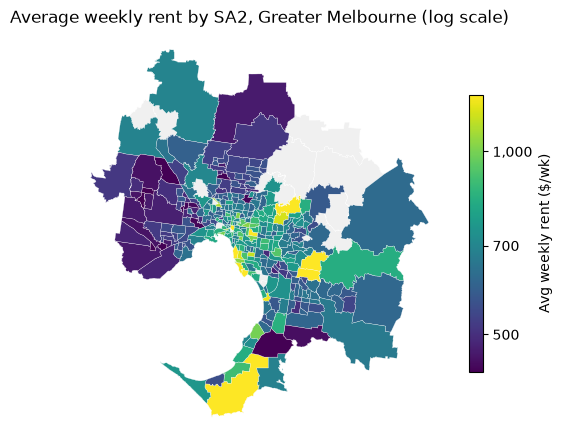

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

rent_by_sa2 = (
    properties_data.groupby("SA2")["weekly_rent_number"]
      .agg(avg_rent="mean", n_properties="size")
      .reset_index()
)

# Greater Melbourne GCCSA only
zones = SA2_zones[SA2_zones["GCC_NAME21"] == "Greater Melbourne"].copy()
if zones.empty:
    raise ValueError(f"No match. GCC names present: {sorted(SA2_zones['GCC_NAME21'].unique())}")

merged = zones.merge(rent_by_sa2, left_on="SA2_NAME21", right_on="SA2", how="left")

matched = merged["avg_rent"].notna().sum()
print(f"{matched} of {len(zones)} Greater Melbourne SA2s have rent data")
print(f"{len(rent_by_sa2) - matched} SA2s in df fall outside Greater Melbourne")

merged = merged[~merged.geometry.is_empty & merged.geometry.notna()]
plot_data = merged[merged["avg_rent"].notna() & (merged["avg_rent"] > 0)]
if plot_data.empty:
    raise ValueError("No SA2s matched — check the join keys before plotting")

vmin, vmax = plot_data["avg_rent"].quantile([0.02, 0.98])
norm = LogNorm(vmin=vmin, vmax=vmax, clip=True)

fig, ax = plt.subplots(figsize=(6, 6))
merged.plot(ax=ax, color="#f0f0f0", edgecolor="white", linewidth=0.3)
plot_data.plot(
    column="avg_rent",
    cmap="viridis",
    norm=norm,
    legend=True,
    legend_kwds={"label": "Avg weekly rent ($/wk)", "shrink": 0.6},
    edgecolor="white",
    linewidth=0.2,
    ax=ax,
)

cbar = fig.axes[-1]
ticks = [t for t in [150, 200, 300, 400, 500, 700, 1000, 1500, 2000, 3000] if vmin <= t <= vmax]
if ticks:
    cbar.set_yticks(ticks)
    cbar.set_yticklabels([f"{t:,}" for t in ticks])
    cbar.minorticks_off()

ax.set_title("Average weekly rent by SA2, Greater Melbourne (log scale)")
ax.set_axis_off()
plt.show()

342 of 361 Greater Melbourne SA2s have listings
total 7,634 listings | median 15 | max 194


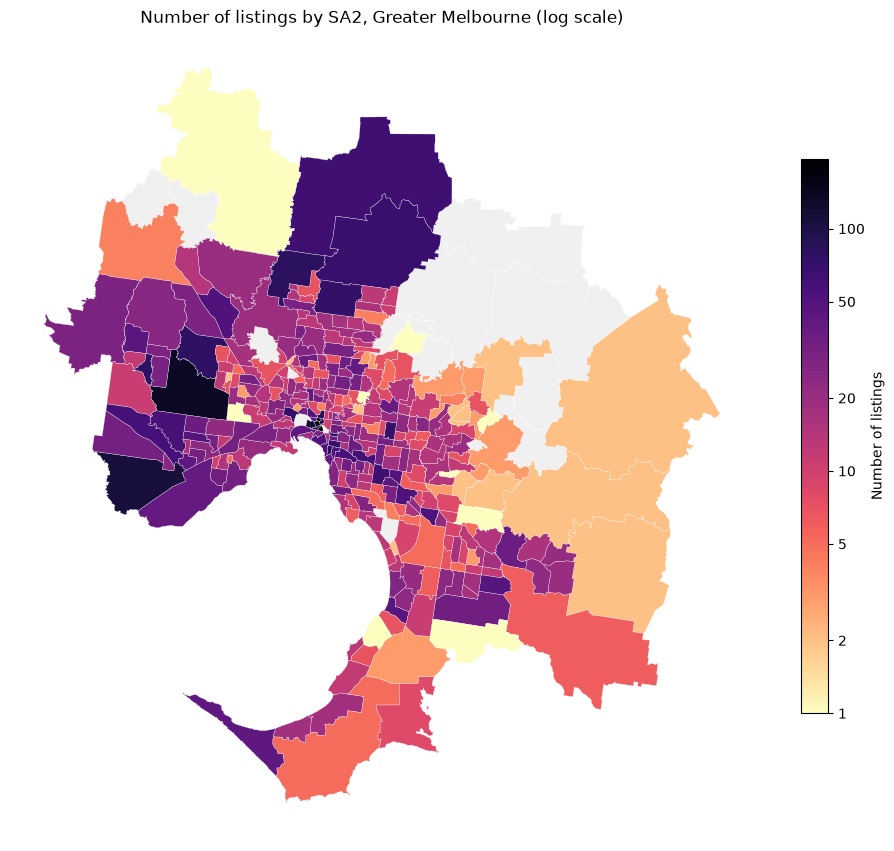

In [12]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

listings_by_sa2 = (
    properties_data.groupby("SA2")
      .size()
      .reset_index(name="n_listings")
)

zones = SA2_zones[SA2_zones["GCC_NAME21"] == "Greater Melbourne"].copy()
if zones.empty:
    raise ValueError(f"No match. GCC names present: {sorted(SA2_zones['GCC_NAME21'].unique())}")

merged = zones.merge(listings_by_sa2, left_on="SA2_NAME21", right_on="SA2", how="left")
merged["n_listings"] = merged["n_listings"].fillna(0)

merged = merged[~merged.geometry.is_empty & merged.geometry.notna()]
plot_data = merged[merged["n_listings"] > 0]
if plot_data.empty:
    raise ValueError("No SA2s matched — check the join keys before plotting")

print(f"{len(plot_data)} of {len(merged)} Greater Melbourne SA2s have listings")
print(f"total {int(merged['n_listings'].sum()):,} listings | "
      f"median {plot_data['n_listings'].median():.0f} | max {int(plot_data['n_listings'].max())}")

norm = LogNorm(vmin=1, vmax=plot_data["n_listings"].max())

fig, ax = plt.subplots(figsize=(12, 12))
merged.plot(ax=ax, color="#f0f0f0", edgecolor="white", linewidth=0.3)
plot_data.plot(
    column="n_listings",
    cmap="magma_r",
    norm=norm,
    legend=True,
    legend_kwds={"label": "Number of listings", "shrink": 0.6},
    edgecolor="white",
    linewidth=0.2,
    ax=ax,
)

cbar = fig.axes[-1]
ticks = [t for t in [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000] if t <= plot_data["n_listings"].max()]
cbar.set_yticks(ticks)
cbar.set_yticklabels([str(t) for t in ticks])
cbar.minorticks_off()

ax.set_title("Number of listings by SA2, Greater Melbourne (log scale)")
ax.set_axis_off()
plt.show()